# Evaluation Notebook

### General Libs

In [1]:
import os
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # 0 (default) = all messages, 1 = INFO messages, 2 = INFO and WARNING messages, 3 = only ERROR messages
logging.getLogger('tensorflow').setLevel(logging.ERROR)  # Suppress TensorFlow INFO and WARNING messages
import sys
import wfdb
import importlib
import seaborn as sns
from matplotlib import pyplot as plt
from tqdm import tqdm

import tensorflow as tf

%matplotlib inline
sns.set_theme(style="white", palette=None)

2024-03-26 15:35:19.838439: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-26 15:35:19.838542: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-26 15:35:19.863726: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


### Specifics Libs

In [2]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
sys.path.append(parent_dir)

In [3]:
from utils.utils import *
from dataloader.dataloader_old import *
from models.data_augmentation import *
from models.deep_lstm import build_model
# from models.resnet18 import build_model
from utils.data_lists import *

## Create the base model and load config file

In [4]:
model_name = "resnet18" # Name of the model to evaluate
config_path = "../configs/config.yml"

# Importing model module
try:
    model_module = importlib.import_module(f"models.{model_name}")
except ImportError as exc:
    raise ValueError(f"Model {model_name} not found: {exc}") from exc
# Importing config
try:
    config = load_config(config_path)
except ValueError as exc:
    print(f"Error: {exc}")

model_params = config["model_params"][model_name]
model_params_dict = {}
for param_dict in model_params:
    model_params_dict.update(param_dict)

In [5]:
#Parameters
BATCH_SIZE = config["batch_size"]
INPUT_SHAPE_0 = config["input_shape"][0]
INPUT_SHAPE_1 = config["input_shape"][1]
OUTPUT_SHAPE = config["output_shape"]
SHIFT = config["shift"]
BATCH_SIZE = config["batch_size"]
DA = config["data_augment"]

# Build the model
backbone_model = model_module.build_model(
    sequence_length=INPUT_SHAPE_0,
    embed_dim=INPUT_SHAPE_1,
    **model_params_dict
)
estimator_model = build_model(embed_dim=INPUT_SHAPE_1)

inputs = tf.keras.layers.Input(shape=(INPUT_SHAPE_0, INPUT_SHAPE_1))
latent = backbone_model(inputs)
outputs = estimator_model(latent)
model = tf.keras.Model(inputs, outputs)

## Generate The Evaluation Dataset Method

In [6]:
# test_dataset = (
#     tf.data.Dataset.from_generator(
#         lambda: create_synced_datasets_generator(
#             path3, emg_te_files_lists, force_te_files_lists,
#             INPUT_SHAPE_0, INPUT_SHAPE_1, SHIFT
#         ),
#         output_signature=(
#             tf.TensorSpec(
#                 shape=(INPUT_SHAPE_0, INPUT_SHAPE_1), dtype=tf.float32
#             ),
#             tf.TensorSpec(shape=(OUTPUT_SHAPE,), dtype=tf.float32),
#         ),
#     )
#     .batch(1)
#     .prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
# )

## Example Result Plots

### Check if it have 20 models

In [7]:
# Base folder for the model logs
if DA:
    base_dir = f"../logs/models/{model_name}/wa_all_fingers/"
else:
    base_dir = f"../logs/models/{model_name}/na_all_fingers/"

# Check if the base directory exists and is a directory
if not os.path.exists(base_dir):
    os.makedirs(base_dir)
if os.path.exists(base_dir) and os.path.isdir(base_dir):
    # List all directories inside the base directory
    sub_dirs = os.listdir(base_dir)
    
    # List to store the found subject numbers
    found_subjects = []
    
    # Loop over the found directories
    for sub_dir in sub_dirs:
        # Check if the directory is a valid directory (not a file)
        if os.path.isdir(os.path.join(base_dir, sub_dir)):
            try:
                # Try to convert the directory name to a subject number
                subject_number = int(sub_dir.split('_')[1])
                found_subjects.append(subject_number)
            except ValueError:
                # If unable to convert to number, skip this directory
                pass
    
    # Check if all 20 subjects are present
    if len(found_subjects) == 20:
        print("All 20 subjects are present.")
    else:
        print("Missing subjects. Last found subject number is:", max(found_subjects))

Missing subjects. Last found subject number is: 1


### Create the path for the subjects dataset

In [8]:
# Path for the dataset
base_path = config["dataset_path"]
# List to store session paths
subjects = []

# Iterate over the 20 subjects
for subject_number in range(1, 21):
    subject_path1 = f"subject{subject_number:02d}_session1/"
    subject_path2 = f"subject{subject_number:02d}_session2/"

    # Path of the first session
    session1_path = os.path.join(base_path, subject_path1)

    # Path of the second session
    session2_path = os.path.join(base_path, subject_path2)

    # Add session paths to the list
    subjects.append([session1_path, session2_path])

### Iterate Over The Models And Dataset

In [9]:
total_predictions, total_force_signal, mse_values = [], [], []

for subject in range(1, max(found_subjects) + 1):
    print("Starting processing for the next subject number:", subject)
    # Create the paths
    path1 = ["../" + subjects[subject][0]]
    path2 = ["../" + subjects[subject][1]]
    path3 = ["../" + subjects[subject][1]]

    # Generate the Evaluation Dataset
    test_dataset = (
        tf.data.Dataset.from_generator(
            lambda: create_synced_datasets_generator(
                path3, emg_te_files_lists, force_te_files_lists,
                INPUT_SHAPE_0, INPUT_SHAPE_1
            ),
            output_signature=(
                tf.TensorSpec(
                    shape=(INPUT_SHAPE_0, INPUT_SHAPE_1), dtype=tf.float16
                ),
                tf.TensorSpec(shape=(OUTPUT_SHAPE,), dtype=tf.float16),
            ),
        )
        .batch(1)
        .prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
    )

    if DA:
        folder = 'wa_all_fingers'
    else:
        folder = 'na_all_fingers'
    # Load The Model
    file_path = f'../logs/models/{model_name}/{folder}/subject_{subject}/'
    model_path = file_path + f'quantized_{model_name}.tflite'

    # Carregar o modelo TFLite
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()
    
    # Obter detalhes do input e output tensors do modelo
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    predictions, force_signal, emg_signal = [], [], []
    mse, num_samples = 0, 0
    for emg, f in tqdm(test_dataset, desc="EMG window"):
        emg = tf.cast(emg, tf.float32)
        interpreter.set_tensor(input_details[0]['index'], emg.numpy())
        interpreter.invoke()
        prediction = interpreter.get_tensor(interpreter.get_output_details()[0]['index'])
        predictions.append(prediction)
        force_signal.append(f)
        emg_signal.append(emg)
        # Compute the MSE
        mse += tf.reduce_mean(tf.square(prediction - f)).numpy()
        num_samples += 1

    # Calculate the error
    mse /= num_samples  # Calculate the average MSE
    mse_values.append(mse)
    
    # Converter a lista de previsões em um tensor
    total_predictions.append(tf.concat(predictions, axis=0))
    total_force_signal.append(tf.concat(force_signal, axis=0))

print("All subjects analysed")

Starting processing for the next subject number: 1


INFO: Created TensorFlow Lite delegate for select TF ops.
INFO: TfLiteFlexDelegate delegate: 2 nodes delegated out of 372 nodes with 2 partitions.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
EMG window: 11975it [01:36, 123.82it/s]


All subjects analysed


### Create a base force signal

In [10]:
predicted_test = np.array([np.array(prediction) for prediction in total_predictions])
outputs = np.array([np.array(forces) for forces in total_force_signal])

In [11]:
# Define the length of the signal
signal_length = len(outputs[0])

# Define the segments
all_lengths = []
x = 299
y = 2395
for i in range(5):
    segment_lengths = [x, 299, 598, 598, 299, signal_length - y]
    x += 2395
    y += 2395
    all_lengths.append(segment_lengths)

# Define the values for each segment
segment_values = []
for i in range(5):
    # segment_values_dim = [0, np.max(normalized_signal[:, :, i]), np.min(normalized_signal[:, :, i]), np.max(normalized_signal[:, :, i]), 0, 0]
    segment_values_dim = [0, 1, -1, 1, 0, 0]
    segment_values.append(segment_values_dim)

# Generate the signal by linearly interpolating between segment values
base_force_signals = []
# Generate signals and store them in the list
for i in range(5):
    # Generate the signal according to the specified pattern
    signal = np.zeros(signal_length)
    start = 0
    for length, value in zip(all_lengths[i], segment_values[i]):
        end = start + length
        signal[start:end] = np.linspace(signal[start - 1], value, length)
        start = end
    # Append the generated signal to the list
    base_force_signals.append(signal)

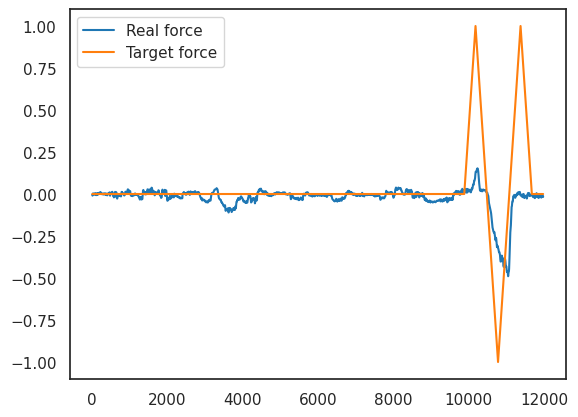

In [12]:
plt.plot(outputs[:, :, 4][0], label="Real force")
plt.plot(base_force_signals[4], label="Target force")

plt.legend()

### Plot the distribution of the predictions

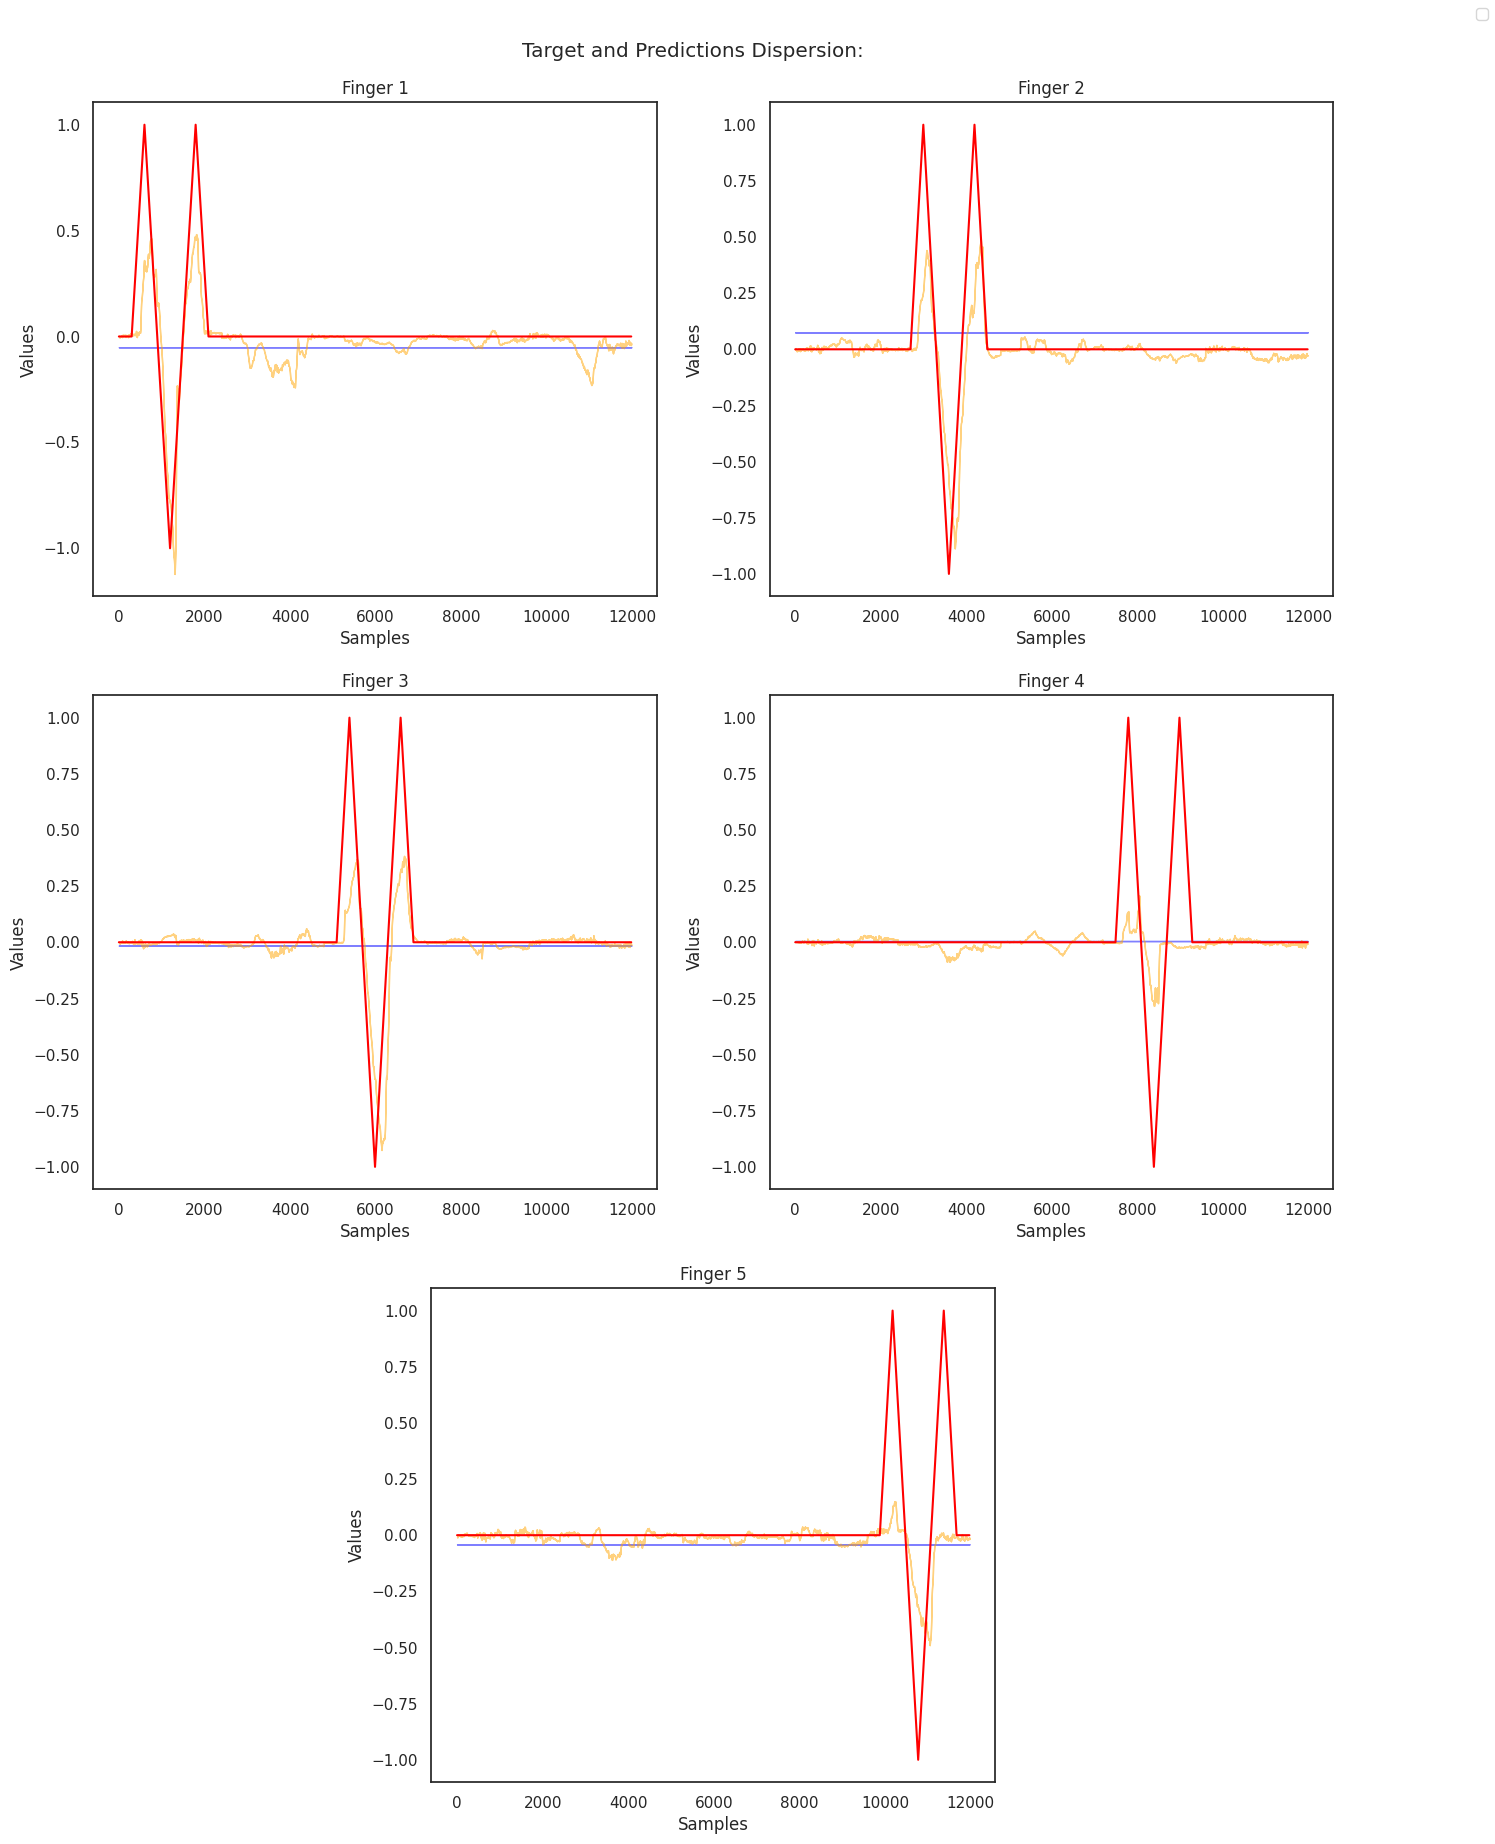

In [13]:
from matplotlib import gridspec as gridspec

plus_minus = "\u00B1"

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

filtered_signals = []
for subject in range(len(predicted_test[0])):
    # Supondo que predicted_test seja uma matriz de dimensão (20, comprimento_do_sinal)
    filtered_signal = butter_lowpass_filter(predicted_test[subject], cutoff, fs,  order=4)
    filtered_signals.append(filtered_signal)

# Create subplots in a 3x4 grid
gs = gridspec.GridSpec(3, 4)
gs.update(wspace=0.5)

# Create the figure
fig = plt.figure(figsize=(16, 20))
fig.suptitle("Target and Predictions Dispersion:")

title = "Target and Predictions Dispersion:"

# Create subplots based on the GridSpec layout
for i in range(5):
    # ax = plt.subplot(gs[i])
    if i == 0:
        ax = plt.subplot(gs[0, :2])
    elif i == 1:
        ax = plt.subplot(gs[0, 2:])
    elif i == 2:
        ax = plt.subplot(gs[1, :2])
    elif i == 3:
        ax = plt.subplot(gs[1, 2:])
    else:
       ax = plt.subplot(gs[2, 1:3])
  
    # predictions = y[:, :, i]
    # forces = normalized_signal[:, :, i]

    # Prediction min/max
    max_values = np.max(filtered_signals, axis=0)
    min_values = np.min(filtered_signals, axis=0)

    # Real force min/max
    max_force_values = np.max(outputs, axis=0)
    min_force_values = np.min(outputs, axis=0)

    # Plot base target for force
    plt.plot(base_force_signals[i], color="red", label="Target force")

    # Plot prediction dispersion
    for prediction in predicted_test:
        x_values = np.arange(0, len(filtered_signals[0]))
        ax.fill_between(x_values, min_values[:, i], max_values[:, i], color='blue', alpha=0.5, label="Dispersion of force prediction of all 20 subjects")

    # Plot real force dispersion
    for force in outputs:
        label = "Dispersion of real force of all 20 subjects"  # Create label for each filled area
        x_values = np.arange(0, len(outputs[0]))
        ax.fill_between(x_values, min_force_values[:, i], max_force_values[:, i], color='orange', alpha=0.5)
        
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

# Turn off the middle subplot
ax = plt.subplot(gs[5])
ax.axis('off')

# Adjust layout
plt.subplots_adjust(top=0.95)
# Add legend
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

# Show the plot
plt.show()

/tmp/ipykernel_3327885/3490579765.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  last_ax.set_xticklabels(samples_to_seconds(last_ax.get_xticks(), sample_rate))


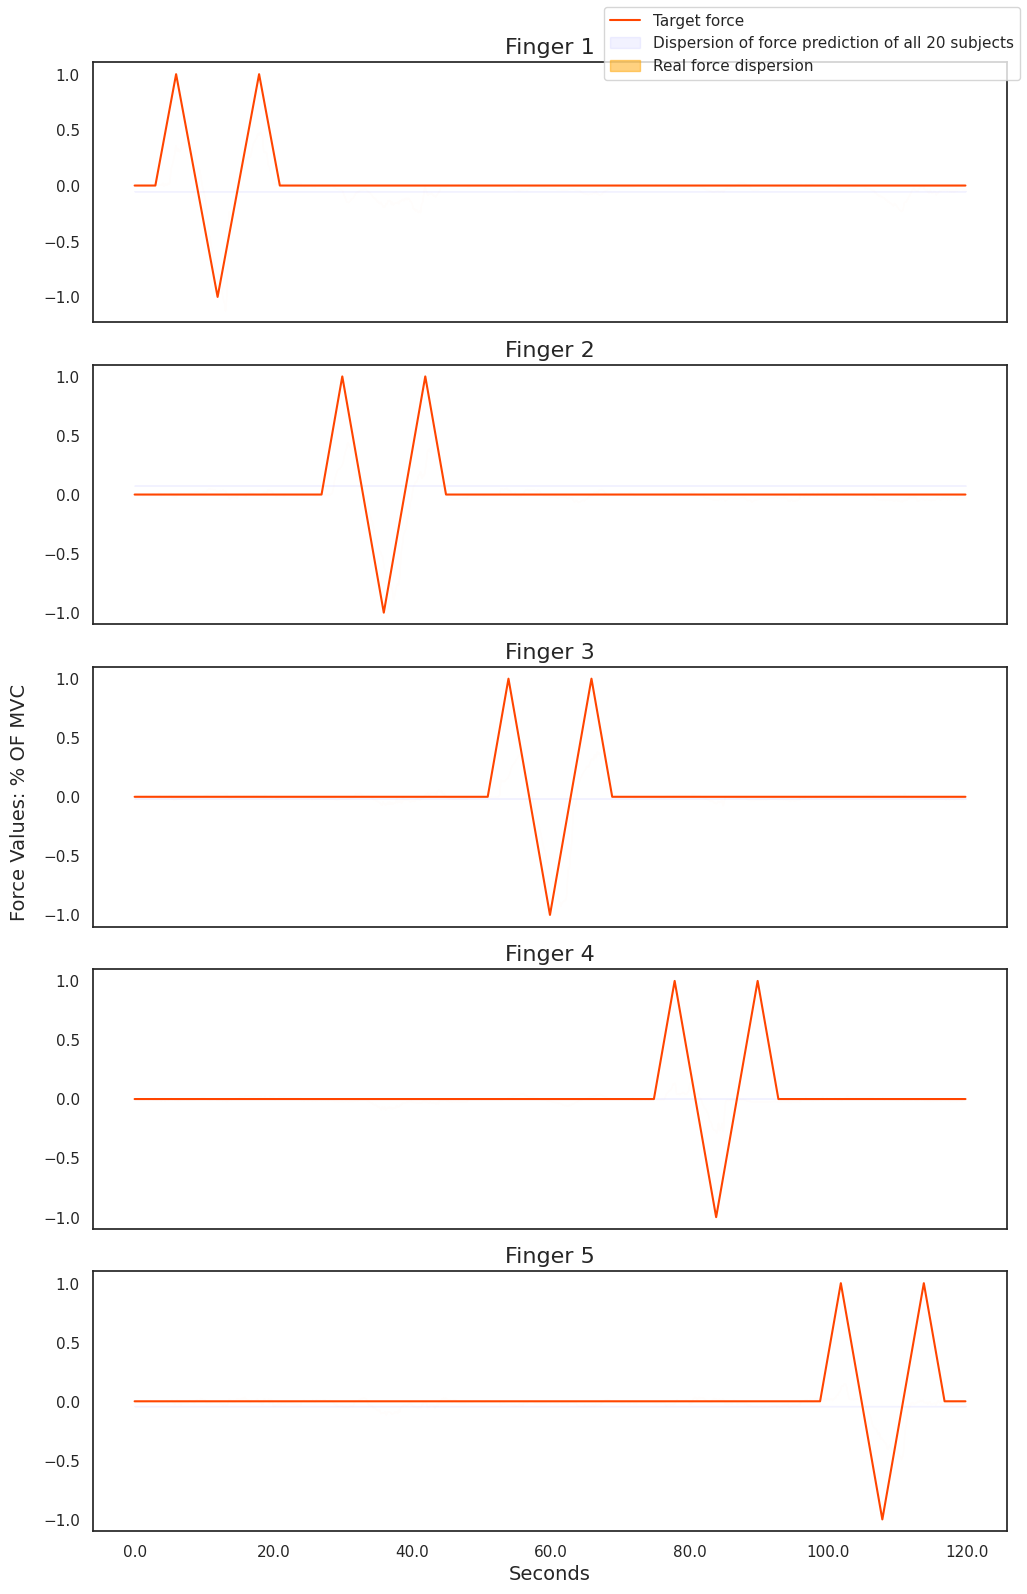

In [14]:
# Define a função para converter de samples para segundos
def samples_to_seconds(samples, sample_rate):
    return samples / sample_rate

# Define a taxa de amostragem (sample rate)
sample_rate = 100  # Exemplo, ajuste conforme sua taxa de amostragem

# Create the figure
fig, axes = plt.subplots(5, 1, figsize=(10, 16))
fig.suptitle("", fontsize=18, y=1.0)

# Create subplots based on the GridSpec layout
for i, ax in enumerate(axes):
    # Define a posição vertical do subplot
    sub_plot_position = 3 - i * 1.5  # Decremento de 1.5 para cada subplot
    
    # predictions = y[:, :, i]
    # forces = outputs[:, :, i]

    # Real force min/max
    max_force_values = np.max(outputs, axis=0)
    min_force_values = np.min(outputs, axis=0)

    # Prediction min/max
    max_values = np.max(filtered_signals, axis=0)
    min_values = np.min(filtered_signals, axis=0)    

    # Plot base target for force
    ax.plot(base_force_signals[i], color="orangered", label="Target force")

    # Plot real force dispersion
    for force in outputs:
        label = "Dispersion of real force of all 20 subjects"  # Create label for each filled area
        x_values = np.arange(0, len(outputs[0]))
        ax.fill_between(x_values, min_force_values[:, i], max_force_values[:, i], color='orange', alpha=0.01)

    # Plot prediction dispersion
    for prediction in filtered_signals:
        x_values = np.arange(0, len(filtered_signals[0]))
        ax.fill_between(x_values, min_values[:, i], max_values[:, i], color='blue', alpha=0.05, label="Dispersion of force prediction of all 20 subjects")

    # Configure the subplot
    ax.set_title(f"Finger {i+1}", fontsize=16)  # Adjust title font size
    ax.xaxis.grid(True, which='minor')
    # ax.set_ylabel("Values", fontsize=14)  # Adjust y-label font size
    
    # Hide x-axis labels for all but the bottom subplot
    if i < len(axes) - 1:
        ax.xaxis.set_ticklabels([])

# Set x-label for the bottom subplot
axes[-1].set_xlabel("Seconds", fontsize=14)  # Adjust x-label font size
# Add a text annotation in the middle left of the figure
fig.text(-0.015, 0.5, 'Force Values: % OF MVC', va='center', rotation='vertical', fontsize=14)

# Add legend
axes[0].fill_between([], [], [], color='orange', alpha=0.5, label="Real force dispersion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

# Ajuste o layout para evitar sobreposição
plt.tight_layout()

# Apply time scale for the last plot
last_ax = axes[-1]
last_ax.set_xticklabels(samples_to_seconds(last_ax.get_xticks(), sample_rate))

# Show the plot
plt.show()

### Statistical Result Of All Subjects

In [15]:
def mean_squared_error(y_true, y_pred):
    """
    Calcula o Erro Quadrático Médio (MSE) entre dois conjuntos de dados.

    Args:
        y_true (numpy.ndarray): O array numpy contendo os valores verdadeiros.
        y_pred (numpy.ndarray): O array numpy contendo os valores previstos.

    Returns:
        float: O MSE entre os valores verdadeiros e os previstos.
    """
    return np.mean((y_true - y_pred)**2)

In [16]:
mse_values = []
for i in range(len(outputs)):
    mse_finger_list = []
    for j in range(5):
        mse_finger = mean_squared_error(outputs[i, :, :][:, j], np.array(base_force_signals)[j])
        mse_finger_list.append(mse_finger)
    mse_values.append(mse_finger_list)

mse_values = np.array(mse_values)
# mse_values = np.array([mean_squared_error(subject, np.array(base_force_signals).reshape((11975, 5))) for subject in normalized_signal])

In [17]:
mean_mse_list = [np.mean(mse) for mse in mse_values]
std_mse_list = [np.std(mse) for mse in mse_values]

mean_mse = np.mean(mse_values)
std_mse = np.std(mse_values)

subjects_number =  np.arange(1, 19)

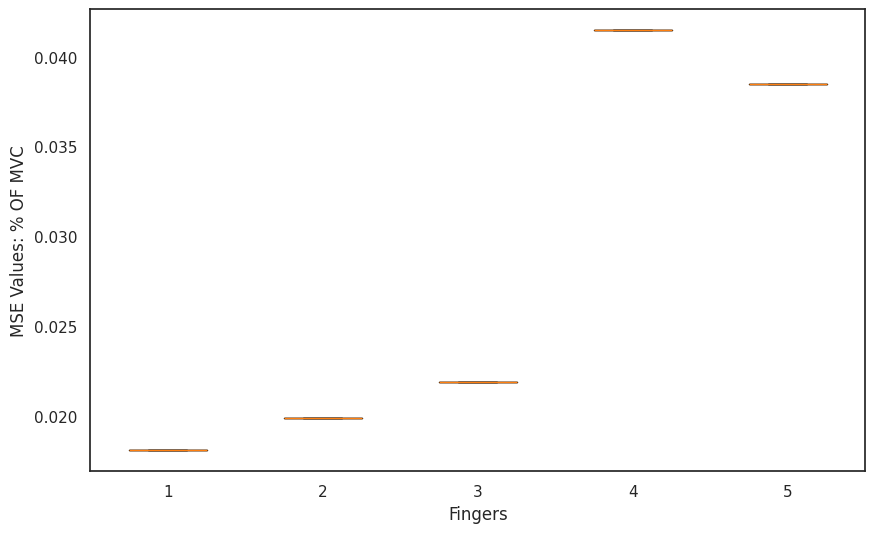

In [18]:
# Cria o boxplot
plt.figure(figsize=(10, 6))
plt.boxplot(mse_values, meanline=True)
# Adiciona rótulo ao eixo x
plt.xlabel('Fingers')
# Adiciona rótulo ao eixo y
plt.ylabel('MSE Values: % OF MVC')
# Adiciona título ao gráfico
# plt.title('Boxplot dos Erros')
# Exibe o gráfico
plt.show()

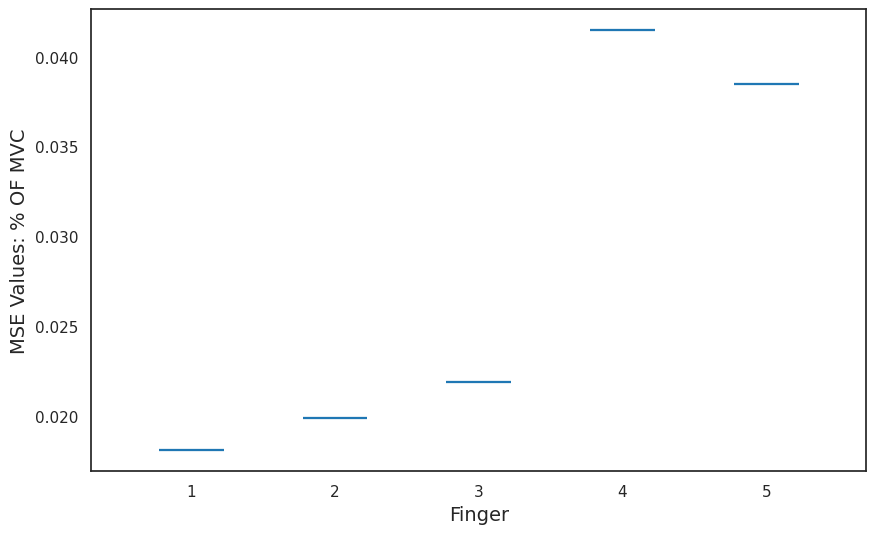

In [19]:
# Create a violin plot
plt.figure(figsize=(10, 6))
parts = plt.violinplot(mse_values, widths=0.9, showmeans=True)

# Set the locations of the violins manually
# plt.xticks(np.arange(1, len(subjects) + 1), subjects_number)

# Add labels and title
plt.xlabel('Finger', fontsize=14)
plt.ylabel('MSE Values: % OF MVC', fontsize=14)
# plt.title('Violin Plot of Data', fontsize=16)

# Show plot
plt.show()

In [20]:
# # Plotagem do gráfico de dispersão com barras de erro
# plt.figure(figsize=(10, 6))
# plt.errorbar(subjects_number, mse_values, yerr=std_mse, fmt='o', color='red')
# plt.xlabel('Sujeito')
# plt.ylabel('MSE')
# plt.title('MSE para cada Sujeito com Desvio Padrão')
# plt.show()

In [21]:
np.max(predicted_test)

0.075506605

In [22]:
np.min(predicted_test)

-0.050841432

In [23]:
mse

0.01736259225514836